# 04 — A term of outreach: how many students are reached before they go silent?

Stages 1–3 scored single weeks. A student-support team works across a whole term: each week it contacts the highest-risk students it has capacity for, and does not re-contact someone it reached recently. This notebook replays that process on **held-out** stage 3 scores for weeks 1–24 and asks:

* **Coverage:** what share of withdrawing students were contacted *while still engaging* (on or before their last VLE activity)?
* **Workload:** how many contacts per 100 students per term does that take?
* **Design choices:** weekly capacity, and the *cool-down* (weeks before the same student can be contacted again).

Comparators: the engagement baseline (cumulative clicks) and a **random** list of the same size. Differences come with paired bootstrap 95% intervals over module presentations.

> **Caveat.** The simulation assumes contact does not change behaviour. It measures who would be *reached* in time, not who would be *retained*; that needs a trial.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from eew.experiments import run_stage4

FIG = pathlib.Path.cwd().parent / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = run_stage4()  # about 3 minutes
curves, cool, diffs = res["curves"], res["cooldowns"], res["differences"]
print(f"Withdrawing students whose last activity falls in weeks 1-24: {curves.withdrawers_in_window.iloc[0]:,}")

Withdrawing students whose last activity falls in weeks 1-24: 5,137


## 1. Coverage against workload

Each point is a weekly capacity (1%, 2.5%, 5%, 7.5%, 10%, 15% or 20% of each cohort), with a 4-week cool-down. The x-axis is total workload: contacts per 100 enrolled students over the term.

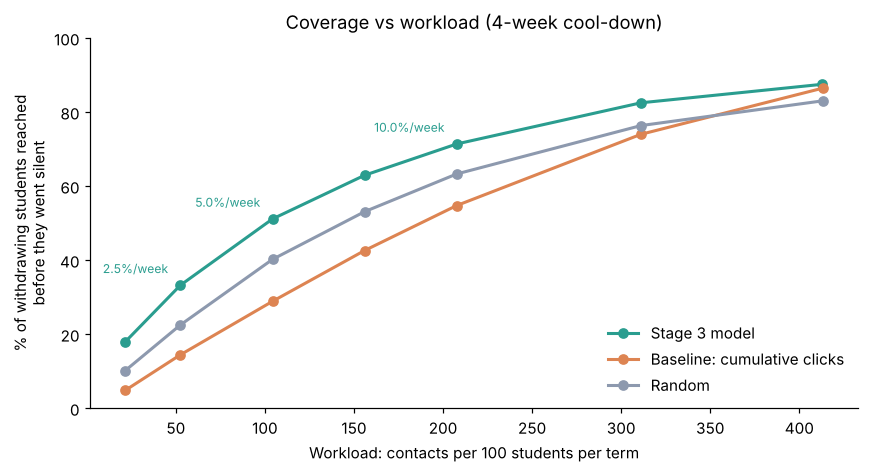

In [2]:
colours = {"Stage 3 model": "#2a9d8f", "Baseline: cumulative clicks": "#DD8452", "Random": "#8d99ae"}
fig, ax = plt.subplots(figsize=(8, 4.4))
for name, c in colours.items():
    r = curves[curves.score == name]
    ax.plot(r.contacts_per_100_students, r.reached_before_silence * 100, marker="o", color=c, label=name, lw=2)
m = curves[curves.score == "Stage 3 model"]
for _, row in m[m.capacity.isin([0.025, 0.05, 0.10])].iterrows():
    ax.annotate(f"{row.capacity:.1%}/week", (row.contacts_per_100_students, row.reached_before_silence * 100),
                textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=8, color="#2a9d8f")
ax.set(xlabel="Workload: contacts per 100 students per term", ylabel="% of withdrawing students reached\nbefore they went silent",
       ylim=(0, 100), title="Coverage vs workload (4-week cool-down)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "stage4_coverage_curve.png", bbox_inches="tight"); plt.show()

In [3]:
d = diffs.copy()
d["coverage gain (pp)"] = [f"{x*100:.1f} [{lo*100:.1f}, {hi*100:.1f}]" for x, lo, hi in zip(d.difference, d.lo, d.hi)]
d.pivot(index="capacity", columns="compared_with", values="coverage gain (pp)")

compared_with,Baseline: cumulative clicks,Random
capacity,,
0.025,"18.8 [16.0, 21.5]","10.7 [8.2, 13.5]"
0.050,"22.3 [18.8, 25.8]","10.9 [8.3, 13.7]"
0.100,"16.6 [14.3, 19.1]","8.1 [5.9, 10.7]"


In [4]:
cols = ["capacity", "reached_before_silence", "contacts_per_100_students", "share_contacted",
        "contacted_who_withdraw", "contacted_who_fail_or_withdraw", "contacts_per_student_reached_in_time", "median_lead_weeks"]
curves.pivot_table(index="capacity", columns="score", values=["reached_before_silence", "contacted_who_fail_or_withdraw",
                   "contacts_per_student_reached_in_time"]).round(3)

contacted_who_fail_or_withdraw                       \
score       Baseline: cumulative clicks Random Stage 3 model   
capacity                                                       
0.010                             0.852  0.406         0.735   
0.025                             0.788  0.409         0.670   
0.050                             0.700  0.413         0.601   
0.075                             0.638  0.422         0.546   
0.100                             0.587  0.430         0.509   
0.150                             0.512  0.443         0.470   
0.200                             0.459  0.449         0.457   

         contacts_per_student_reached_in_time                        \
score             Baseline: cumulative clicks  Random Stage 3 model   
capacity                                                              
0.010                                  26.036  12.344         6.990   
0.025                                  21.147  13.567         9.185   
0.050                                  20.968  15.059        11.842   
0.075                                  21.261  17.058        14.393   
0.100                                  22.026  19.058        16.895   
0.150                                  24.416  23.662        21.897   
0.200                                  27.748  28.903        27.407   

              reached_before_silence                       
score    Baseline: cumulative clicks Random Stage 3 model  
capacity                                                   
0.010                          0.048  0.101         0.179  
0.025                          0.144  0.225         0.332  
0.050                          0.289  0.402         0.511  
0.075                          0.426  0.531         0.629  
0.100                          0.547  0.633         0.714  
0.150                          0.740  0.763         0.825  
0.200                          0.864  0.830         0.875

### Why the baseline is worse than random

The baseline keeps ranking the same low-activity students at the top. Many of them have already gone silent or will fail rather than withdraw. With a cool-down it cycles through the same pool, while a random list spreads contacts across far more students. A model that ranks students on *upcoming* disengagement avoids that trap.

The baseline is not useless, though: 70–85% of the students it contacts will fail *or* withdraw (the model: 51–74%; random: about 41%). It finds students who are struggling academically, which suits academic support, but not retention outreach that needs to happen before a student leaves.

## 2. The cool-down is a design choice, not a detail

At 5% weekly capacity with the stage 3 model: a longer cool-down spreads contacts over more students. That raises coverage, but a smaller share of contacts goes to students who actually withdraw.

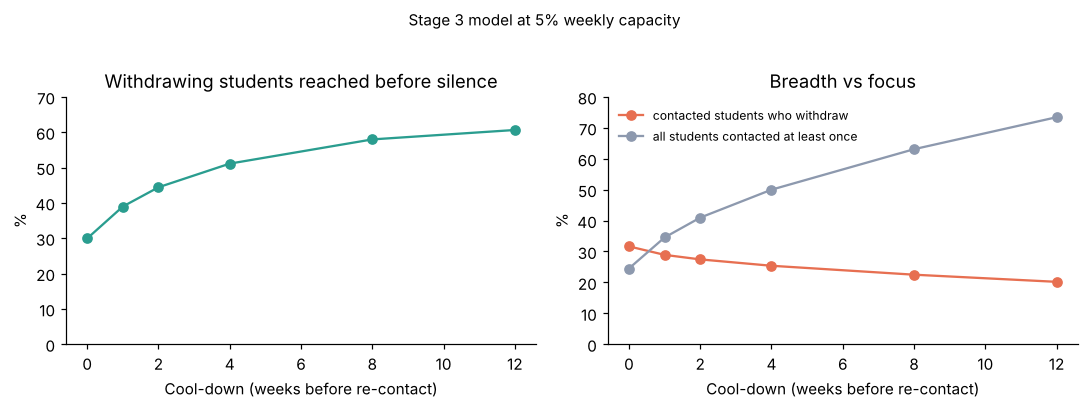

,cooldown_weeks,reached_before_silence,share_contacted,contacted_who_withdraw,contacts_per_student_reached_in_time
0,0,0.299,0.245,0.316,20.218
1,1,0.390,0.345,0.289,15.532
2,2,0.444,0.410,0.274,13.627
3,4,0.511,0.500,0.254,11.842
4,8,0.580,0.631,0.225,10.442
5,12,0.606,0.734,0.202,9.983


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(cool.cooldown_weeks, cool.reached_before_silence * 100, marker="o", color="#2a9d8f")
axes[0].set(xlabel="Cool-down (weeks before re-contact)", ylabel="%", title="Withdrawing students reached before silence", ylim=(0, 70))
axes[1].plot(cool.cooldown_weeks, cool.contacted_who_withdraw * 100, marker="o", color="#e76f51", label="contacted students who withdraw")
axes[1].plot(cool.cooldown_weeks, cool.share_contacted * 100, marker="o", color="#8d99ae", label="all students contacted at least once")
axes[1].set(xlabel="Cool-down (weeks before re-contact)", ylabel="%", title="Breadth vs focus", ylim=(0, 80))
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Stage 3 model at 5% weekly capacity", y=1.02, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "stage4_cooldown.png", bbox_inches="tight"); plt.show()
cool[["cooldown_weeks", "reached_before_silence", "share_contacted", "contacted_who_withdraw", "contacts_per_student_reached_in_time"]].round(3)

## 3. Findings

1. **At realistic capacity, the model reaches more withdrawing students before they go silent.** At 2.5% of each cohort per week it reaches 33%, against 22% for a random list; at 5% per week, 51% against 40%. That is about 11 more students in every 100, with paired intervals of roughly 8–14 points. In staffing terms, 5% per week is about 50 contacts per week per 1,000 students.
2. **The engagement baseline does worse than random over a term** (14% at 2.5%, 29% at 5%). It keeps returning to the same low-activity students, many of whom have already gone or will fail. The model beats it by 17–22 points.
3. **High capacity hides the differences.** At 10% per week with a 4-week cool-down, three-quarters of all students are contacted at least once during the term, so even a random list reaches 63% of withdrawers. Comparing tools only makes sense at a workload a team can sustain.
4. **The cool-down matters as much as the model.** Without one, 5% weekly capacity reaches only 30% of withdrawers, because the same students are contacted again and again. A 4-week cool-down reaches 51%; 8–12 weeks reaches 58–61%, but a smaller share of contacts then goes to students who withdraw (25% falls to 20%). This is a policy choice the institution should make deliberately.
5. **Each student reached in time costs about 9–12 contacts at 2.5–5% capacity,** against about 21 for the baseline and 14–15 for random.

**Limitations:** no intervention effect is modelled; capacity is a fixed share of each cohort (real teams may pool across modules); weeks 1–24 only; the model's scores are out-of-fold, but the policy settings were chosen on the same data.